### Building A Basic Chatbot With Langraph API

In [3]:
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages

In [4]:
class State(TypedDict):
    # Messages have the type "list". The `add_messages` function
    # in the annotation defines how this state key should be updated
    # (in this case, it appends messages to the list, rather than overwriting them)
    messages:Annotated[list,add_messages]

graph_builder=StateGraph(State)

In [5]:
graph_builder

In [6]:
import os
from dotenv import load_dotenv
load_dotenv()

True

In [7]:
from langchain_groq import ChatGroq
from langchain.chat_models import init_chat_model

llm=ChatGroq(model="openai/gpt-oss-120b")

In [8]:
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.8.4', 'langchain': '1.5.2', 'langchain-groq': '1.2.1'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2025-08-05', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000002585FAD4440>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000002585FAD4D70>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [9]:
## Mnode funcationality
def chatbot(state:State):
    return {"messages":[llm.invoke(state["messages"])]}

In [10]:
graph_builder=StateGraph(State)

## Adding node
graph_builder.add_node("llmchatbot",chatbot)
## Adding Edges
graph_builder.add_edge(START,"llmchatbot")
graph_builder.add_edge("llmchatbot", END)

## compile the graph
graph=graph_builder.compile()

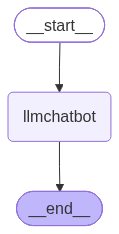

In [11]:
## Visualize the graph
from IPython.display import Image,display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass

In [12]:
graph.invoke({"messages":"Hi"})

{'messages': [HumanMessage(content='Hi', additional_kwargs={}, response_metadata={}, id='fb83d6ab-de2b-4042-81a9-c8762fa94646'),
  AIMessage(content='Hello! How can I help you today?', additional_kwargs={'reasoning_content': 'The user says "Hi". We need to respond appropriately, friendly greeting. No special constraints. Just respond.'}, response_metadata={'token_usage': {'completion_tokens': 41, 'prompt_tokens': 72, 'total_tokens': 113, 'completion_time': 0.085956817, 'completion_tokens_details': {'reasoning_tokens': 23}, 'prompt_time': 0.003024587, 'prompt_tokens_details': None, 'queue_time': 0.249131859, 'total_time': 0.088981404}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_e1a78f200e', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a21115-c671-768e-a131-d48614ab3c16-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 72, 'output_tokens': 41, 'total_tokens': 113, 'output_token

In [13]:
from langchain_core.messages import HumanMessage

for event in graph.stream({"messages": [HumanMessage(content="Hi How are you?")]}):
    for value in event.values():
        print(value["messages"][-1].content)

{
  "response": "Hello! I'm doing well, thank you. How can I assist you today?",
  "function_calls": []
}


### Chatbot With Tools

In [14]:
from langchain_tavily import TavilySearch

tool=TavilySearch(max_results=2)
tool.invoke("what is langgraph")

{'query': 'what is langgraph',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.ibm.com/think/topics/langgraph',
   'title': 'What is LangGraph? | IBM',
   'content': 'LangGraph, created by LangChain, is an open source AI agent framework designed to build, deploy and manage complex generative AI agent workflows. It provides a set of tools and libraries that enable users to create, run and optimize large language models (LLMs) in a scalable and efficient manner. At its core, LangGraph uses the power of graph-based architectures to model and manage the intricate relationships between various components of an AI agent workflow. [...] LangGraph illuminates the processes within an AI workflow, allowing full transparency of the agent’s state. Within LangGraph, the “state” feature serves as a memory bank that records and tracks all the valuable information processed by the AI system. It’s similar to a digital notebook where the system captures an

In [15]:
## Custom function
def multiply(a: int, b: int) -> int:
    """Multiply a and b

    Args:
        a (int): first int
        b (int): second int

    Returns:
        int: output int
    """
    return a * b


In [16]:
tools=[tool,multiply]

In [17]:
llm_with_tool=llm.bind_tools(tools)

In [18]:
llm_with_tool

_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.8.4', 'langchain': '1.5.2', 'langchain-groq': '1.2.1'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2025-08-05', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000002585FAD4440>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000002585FAD4D70>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********')), kwargs={'tools': [{'type': 'function', 'function': {'name': 'tavily_search', 'description': 'A search engine optimized for 

In [19]:
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph.message import add_messages

class State(TypedDict):
    messages: Annotated[list, add_messages]


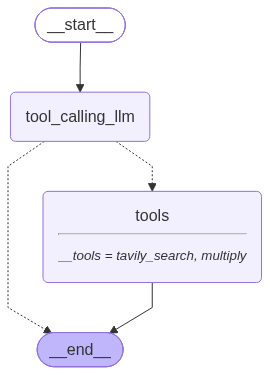

In [20]:
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

## Node definition
def tool_calling_llm(state: State):
    return {"messages": [llm_with_tool.invoke(state["messages"])]}

## Graph
builder = StateGraph(State)
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools", ToolNode(tools))

## Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools", END)

## Compile
graph = builder.compile()

display(Image(graph.get_graph().draw_mermaid_png()))


In [21]:
response = graph.invoke({
    "messages": [("user", "what is the recent ai news")]
})


In [22]:
for m in response['messages']:
    m.pretty_print()


================================ Human Message =================================

what is the recent ai news
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_e3b91539-fdf6-43cb-8edf-bf7309280394)
 Call ID: fc_e3b91539-fdf6-43cb-8edf-bf7309280394
  Args:
    query: latest AI news November 2026
    search_depth: advanced
    time_range: month
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news November 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://joinaiweek.com/blog/ai-news-roundup-november-2026", "title": "AI news roundup, November 2026: Nvidia, Anthropic IPO, new models | AI Week", "content": "## Anthropic heads to Nasdaq\n\nAnthropic, the maker of Claude, set a price range of $70 to $78 per share and plans to price its IPO on November 18, with trading expected on Nasdaq under the ticker ANT on Nove

In [23]:
response = graph.invoke({
    "messages": [("user", "what is 2 multiplied  by 3")]
})

In [24]:
response
for m in response['messages']:
    m.pretty_print()


================================ Human Message =================================

what is 2 multiplied  by 3
================================== Ai Message ==================================

2 multiplied by 3 equals **6**.


In [25]:
response = graph.invoke({
    "messages": [("user", "what is 2 multiplied  by 3 and then multiply by 10")]
})
response
for m in response['messages']:
    m.pretty_print()


================================ Human Message =================================

what is 2 multiplied  by 3 and then multiply by 10
================================== Ai Message ==================================

\(2 \times 3 = 6\)

\(6 \times 10 = 60\)

So the result is **60**.


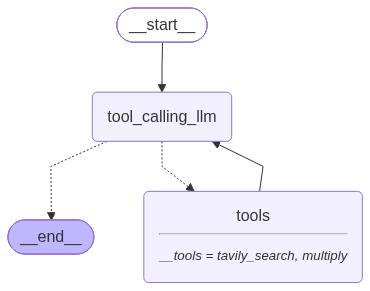

In [26]:
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

## Node definition
def tool_calling_llm(state: State):
    return {"messages": [llm_with_tool.invoke(state["messages"])]}

## Graph
builder = StateGraph(State)
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools", ToolNode(tools))

## Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools", "tool_calling_llm")

## Compile
graph = builder.compile()

display(Image(graph.get_graph().draw_mermaid_png()))


In [27]:
response = graph.invoke({
    "messages": [("user", "what is the recent ai news and then 2 multiply by 10")]
})
response
for m in response['messages']:
    m.pretty_print()


================================ Human Message =================================

what is the recent ai news and then 2 multiply by 10
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_7e54dda7-9a8e-41ef-987f-71af4e7811f3)
 Call ID: fc_7e54dda7-9a8e-41ef-987f-71af4e7811f3
  Args:
    query: latest AI news November 2026
    search_depth: fast
    time_range: day
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news November 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.philanthropy.com/solutions/playbooks/year-end-fundraising-in-2026-trends-and-tips/", "title": "Year-end fundraising in 2026: trends and tips - Chronicle of Philanthropy", "score": 1.0, "published_date": "Tue, 24 Nov 2026 12:00:00 GMT", "content": "Access courtesy of — You're on their network. # Year-end fundraising in 2

### Add memory saver

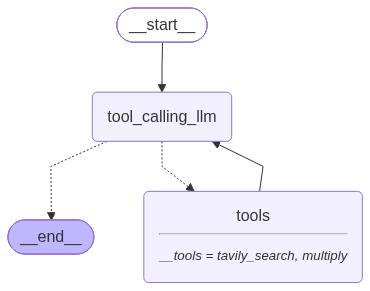

In [28]:
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.checkpoint.memory import MemorySaver

## Node definition
def tool_calling_llm(state: State):
    return {"messages": [llm_with_tool.invoke(state["messages"])]}

## Graph
builder = StateGraph(State)
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools", ToolNode(tools))

## Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    tools_condition
)
builder.add_edge("tools", "tool_calling_llm")

## Initialize MemorySaver and Compile
memory = MemorySaver()
graph = builder.compile(checkpointer=memory)

display(Image(graph.get_graph().draw_mermaid_png()))


In [29]:
config = {"configurable": {"thread_id": "1"}}

# First turn
response = graph.invoke(
    {"messages": [("user", "Hi, my name is Musab.")]},
    config=config
)
response["messages"][-1].pretty_print()

# Second turn (using the same thread_id remembers the previous turn)
response = graph.invoke(
    {"messages": [("user", "What is my name?")]},
    config=config
)
response["messages"][-1].pretty_print()


================================== Ai Message ==================================

Hello Musab! 👋 Nice to meet you. How can I assist you today?
================================== Ai Message ==================================

Your name is Musab.


### Streaming

In [30]:
from langgraph.checkpoint.memory import MemorySaver
MemorySaver=MemorySaver()

In [31]:
def superbot(state: State):
    return {"messages": [llm.invoke(state['messages'])]}


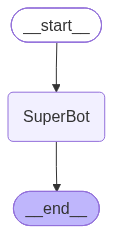

In [32]:
graph = StateGraph(State)

## node
graph.add_node("SuperBot", superbot)
## Edges
graph.add_edge(START, "SuperBot")
graph.add_edge("SuperBot", END)

graph_builder = graph.compile(checkpointer=memory)

## Display
from IPython.display import Image, display
display(Image(graph_builder.get_graph().draw_mermaid_png()))


In [39]:
## Invocation
config = {"configurable": {"thread_id": "1"}}
graph_builder.invoke({'messages': "Hi, My name is Musab And I like chess"}, config)


{'messages': [HumanMessage(content='Hi, my name is Musab.', additional_kwargs={}, response_metadata={}, id='6028588b-738d-44ac-a423-0aaa8fb39d8e'),
  AIMessage(content='Hello Musab! 👋 Nice to meet you. How can I assist you today?', additional_kwargs={'reasoning_content': 'The user says "Hi, my name is Musab." Probably a greeting. Should respond friendly, ask how can I help.'}, response_metadata={'token_usage': {'completion_tokens': 54, 'prompt_tokens': 350, 'total_tokens': 404, 'completion_time': 0.112157743, 'completion_tokens_details': {'reasoning_tokens': 27}, 'prompt_time': 0.015494769, 'prompt_tokens_details': None, 'queue_time': 0.248788378, 'total_time': 0.127652512}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_e1a78f200e', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a21116-8bfd-71e6-8b4d-3ec1bb4eb99b-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 350, 'output_token

### Streaming

Methods: .stream() and astream()

• These methods are sync and async methods for streaming back results.

Additional parameters in streaming modes for graph state

• values : This streams the full state of the graph after each node is called.

• updates : This streams updates to the state of the graph after each node is called.


In [40]:
# Create a thread
config = {"configurable": {"thread_id": "3"}}

for chunk in graph_builder.stream({'messages':"Hi,My name is Musab And I like chess"},config,stream_mode="updates"):
    print(chunk)


{'SuperBot': {'messages': [AIMessage(content='Hey Musab! 👋 Great to see you back. Since you love chess, how about we dive straight into a little brain‑teaser to warm up those tactical muscles?\n\n### ♟️ Quick Puzzle – “Mate in 2”\n\n**Position (White to move):**\n\n```\n8  r  .  .  .  .  r  k .\n7  .  p  .  .  .  p  . .\n6  .  .  p  .  .  .  p .\n5  .  .  .  q  .  .  . .\n4  .  .  .  .  N  .  . .\n3  .  .  .  .  .  .  . .\n2  P  P  P  P  .  P  P  P\n1  R  .  .  Q  K  .  R  .\n   a  b  c  d  e  f  g  h\n```\n\n- White pieces: King\u202fe1, Queen\u202fd1, Rook\u202fa1, Rook\u202fh1, Knight\u202fe4, Pawns\u202fa2\u202fb2\u202fc2\u202fd2\u202ff2\u202fg2\u202fh2  \n- Black pieces: King\u202fg8, Queen\u202fd5, Rook\u202fa8\u202ff8, Pawns\u202fb7\u202ff7\u202fc6\u202fg6\n\n**Task:** Find the move for White that forces checkmate on the next move, regardless of Black’s response.\n\n---\n\n### 🧩 Solution\n\n1. **1.\u202fQe2!** – The queen slides to e2, delivering a *double attack*: it threatens 

In [41]:
# Create a thread
config = {"configurable": {"thread_id": "3"}}

for chunk in graph_builder.stream({'messages':"Hi,My name is Musab And I like chess"},config,stream_mode="values"):
    print(chunk)


{'messages': [HumanMessage(content='Hi,My name is Krish And I like cricket', additional_kwargs={}, response_metadata={}, id='80179a13-4c47-4439-a738-08f471a319be'), AIMessage(content='Hey Krish! 👋 Great to meet you. Cricket’s such an exciting sport—do you have a favorite team or player? Are you more into watching the matches, playing yourself, or maybe both? Let’s chat!', additional_kwargs={'reasoning_content': 'The user says hi, name and interest. We need to respond. Should be friendly, maybe ask about cricket, ask more. No disallowed content. Just respond.'}, response_metadata={'token_usage': {'completion_tokens': 90, 'prompt_tokens': 82, 'total_tokens': 172, 'completion_time': 0.187716058, 'completion_tokens_details': {'reasoning_tokens': 35}, 'prompt_time': 0.013105942, 'prompt_tokens_details': None, 'queue_time': 0.256604259, 'total_time': 0.200822}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_9241e9962b', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'l

In [42]:
# Create a thread
config = {"configurable": {"thread_id": "4"}}

for chunk in graph_builder.stream({'messages':"Hi,My name is Musab And I like chess"},config,stream_mode="updates"):
    print(chunk)


{'SuperBot': {'messages': [AIMessage(content='Hello Musab! 👋 Great to meet you.  \nI’m a big fan of chess too—there’s always something new to learn on the board. Do you have a favorite opening or a particular style of play you enjoy? Whether you’re into sharp tactics, solid positional games, or just love watching classic matches, I’m happy to chat about it!', additional_kwargs={'reasoning_content': 'We need to respond. The user says hi, introduces themselves, likes chess. We can respond friendly, ask about their chess interests, maybe ask about favorite openings, etc. No policy issues. Should be brief but engaging.'}, response_metadata={'token_usage': {'completion_tokens': 128, 'prompt_tokens': 82, 'total_tokens': 210, 'completion_time': 0.266431237, 'completion_tokens_details': {'reasoning_tokens': 46}, 'prompt_time': 0.003217279, 'prompt_tokens_details': None, 'queue_time': 0.24833224, 'total_time': 0.269648516}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_c868cf1e

In [43]:
for chunk in graph_builder.stream({'messages':"I also like badminton"},config,stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content='Hi,My name is Musab And I like chess', additional_kwargs={}, response_metadata={}, id='cff36493-4dd2-4ce7-aaa1-fa1eadd4aac2'), AIMessage(content='Hello Musab! 👋 Great to meet you.  \nI’m a big fan of chess too—there’s always something new to learn on the board. Do you have a favorite opening or a particular style of play you enjoy? Whether you’re into sharp tactics, solid positional games, or just love watching classic matches, I’m happy to chat about it!', additional_kwargs={'reasoning_content': 'We need to respond. The user says hi, introduces themselves, likes chess. We can respond friendly, ask about their chess interests, maybe ask about favorite openings, etc. No policy issues. Should be brief but engaging.'}, response_metadata={'token_usage': {'completion_tokens': 128, 'prompt_tokens': 82, 'total_tokens': 210, 'completion_time': 0.266431237, 'completion_tokens_details': {'reasoning_tokens': 46}, 'prompt_time': 0.003217279, 'prompt_tokens_detai

In [44]:
config = {"configurable": {"thread_id": "5"}}

async for event in graph_builder.astream_events({"messages":["Hi My name is Musab and I like to play chess"]},config,version="v2"):
    print(event)


{'event': 'on_chain_start', 'data': {'input': {'messages': ['Hi My name is Musab and I like to play chess']}}, 'name': 'LangGraph', 'tags': [], 'run_id': '01a21132-faa0-7455-91f4-e0d94b14a4cb', 'metadata': {'thread_id': '5', 'ls_integration': 'langgraph'}, 'parent_ids': []}
{'event': 'on_chain_start', 'data': {'input': {'messages': [HumanMessage(content='Hi My name is Musab and I like to play chess', additional_kwargs={}, response_metadata={}, id='7928fbc7-1f0e-4ffe-8f66-b49e3b7fd1c5')]}}, 'name': 'SuperBot', 'tags': ['graph:step:1'], 'run_id': '01a21132-faa2-7027-8535-48b62a5b63e6', 'metadata': {'thread_id': '5', 'ls_integration': 'langgraph', 'langgraph_step': 1, 'langgraph_node': 'SuperBot', 'langgraph_triggers': ('branch:to:SuperBot',), 'langgraph_path': ('__pregel_pull', 'SuperBot'), 'langgraph_checkpoint_ns': 'SuperBot:437b66f9-c182-3057-66f8-f6f725e9d5ee'}, 'parent_ids': ['01a21132-faa0-7455-91f4-e0d94b14a4cb']}
{'event': 'on_chat_model_start', 'data': {'input': {'messages': [[H